# Лабораторная работа: Теория катастроф в IT-системах
## Катастрофа «сборка» на примере веб-сервиса с балансировщиком нагрузки

**Цель работы:** смоделировать катастрофу «сборка», построить бифуркационное множество и экспериментально подтвердить эффект **гистерезиса** — причину внезапных сбоев сервисов при плавном росте нагрузки.

## 1. Задаём потенциал и параметры

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

np.set_printoptions(precision=4, suppress=True)

def V(x, u, v):
    # потенциал катастрофы сборки
    return x**4 - u*x**2 + v*x

def force(x, u, v):
    # -dV/dx : правая часть уравнения движения  x' = -(4x^3 - 2ux + v)
    return -(4*x**3 - 2*u*x + v)

def equilibria(v, u):
    # вещественные корни 4x^3 - 2ux + v = 0 (положения равновесия), по возрастанию
    r = np.roots([4, 0, -2*u, v])
    return np.sort(r[np.abs(r.imag) < 1e-9].real)

def is_stable(x, u):
    # устойчивость: d/dx[-(4x^3-2ux+v)] = -(12x^2 - 2u) < 0
    return 12*x**2 - 2*u > 0

u = 2.0                              # число инстансов (фиксировано в основном эксперименте)
v_c = np.sqrt(8*u**3 / 27)           # теоретическая точка катастрофы: 8u^3 = 27 v^2
v_max = 3.0                          # трафик меняется от -v_max до +v_max
rate = 0.01                          # скорость изменения трафика (медленная, «адиабатическая»)

print(f"u = {u},  критический трафик |v_c| = sqrt(8u^3/27) = {v_c:.4f}")
print(f"Диапазон трафика [{-v_max}, {v_max}], скорость изменения v: {rate} за единицу времени")

u = 2.0,  критический трафик |v_c| = sqrt(8u^3/27) = 1.5396
Диапазон трафика [-3.0, 3.0], скорость изменения v: 0.01 за единицу времени


## 2. Бифуркационное множество $8u^3=27v^2$

Положения равновесия — корни $4x^3-2ux+v=0$. Число вещественных корней меняется там, где дискриминант кубики равен нулю: для $x^3+px+q=0$ это $4p^3+27q^2=0$, а здесь $p=-u/2$, $q=v/4$, откуда $-\tfrac{u^3}{2}+\tfrac{27v^2}{16}=0\iff 8u^3=27v^2$.

Внутри области $8u^3>27v^2$ существуют **три** равновесия (два устойчивых и одно неустойчивое между ними) — система **бистабильна**. Снаружи — одно.

Сначала проверим это численно, а затем построим множество.

In [ ]:
# Проверка: число вещественных корней кубики меняется ровно на кривой 8u^3 = 27 v^2
print(f"{'u':>5} {'v':>8} {'8u^3-27v^2':>12} {'число равновесий':>18}")
for uu, vv in [(2.0, 0.0), (2.0, 1.4), (2.0, 1.53), (2.0, v_c), (2.0, 1.55), (2.0, 2.5), (1.0, 0.5), (1.0, 0.6)]:
    n = len(equilibria(vv, uu))
    print(f"{uu:5.2f} {vv:8.4f} {8*uu**3 - 27*vv**2:12.4f} {n:18d}")

    u        v   8u^3-27v^2   число равновесий
 2.00   0.0000      64.0000                  3
 2.00   1.4000      11.0800                  3
 2.00   1.5300       0.7957                  3
 2.00   1.5396      -0.0000                  1
 2.00   1.5500      -0.8675                  1
 2.00   2.5000    -104.7500                  1
 1.00   0.5000       1.2500                  3
 1.00   0.6000      -1.7200                  1


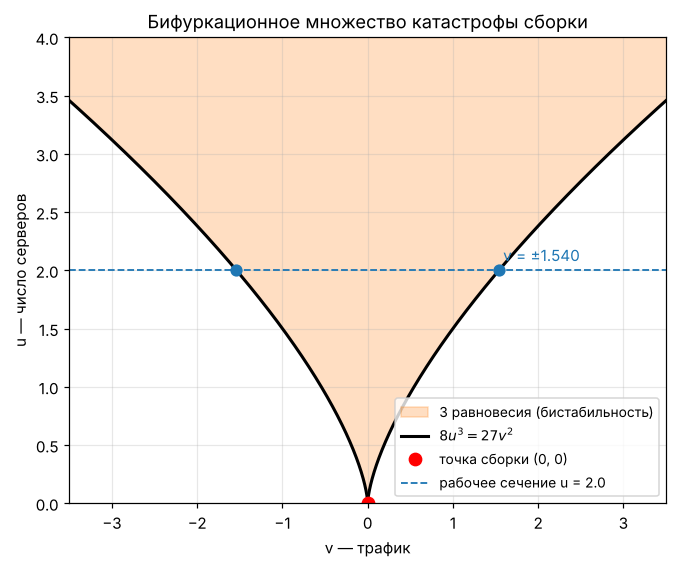

In [ ]:
uu = np.linspace(0, 4, 400)
vv = np.sqrt(8*uu**3/27)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.fill_betweenx(uu, -vv, vv, color="tab:orange", alpha=0.25, label="3 равновесия (бистабильность)")
ax.plot(vv, uu, "k", lw=2, label=r"$8u^3=27v^2$")
ax.plot(-vv, uu, "k", lw=2)
ax.plot(0, 0, "ro", ms=8, label="точка сборки (0, 0)")
ax.axhline(u, color="tab:blue", ls="--", lw=1.2, label=f"рабочее сечение u = {u}")
ax.plot([-v_c, v_c], [u, u], "o", color="tab:blue", ms=7)
ax.text(v_c + 0.05, u + 0.08, f"v = ±{v_c:.3f}", color="tab:blue")
ax.set_xlabel("v — трафик")
ax.set_ylabel("u — число серверов")
ax.set_title("Бифуркационное множество катастрофы сборки")
ax.set_xlim(-3.5, 3.5); ax.set_ylim(0, 4)
ax.legend(loc="lower right", fontsize=9); ax.grid(alpha=0.3)
plt.show()

## 3. Потенциал при разных значениях трафика

Шарик скатывается в минимум потенциала. Внутри бистабильной зоны ($|v|<v_c$) у потенциала два минимума, вне её — один.

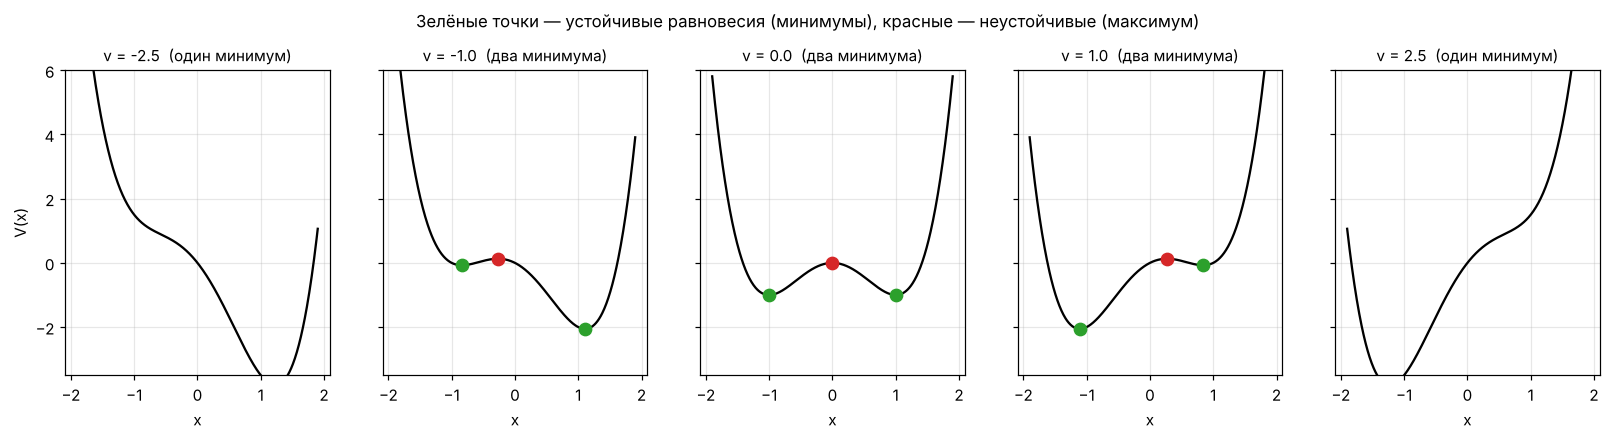

In [ ]:
xs = np.linspace(-1.9, 1.9, 600)
vals = [-2.5, -1.0, 0.0, 1.0, 2.5]

fig, axes = plt.subplots(1, len(vals), figsize=(18, 3.6), sharey=True)
for ax, vv_ in zip(axes, vals):
    ax.plot(xs, V(xs, u, vv_), "k")
    for xe in equilibria(vv_, u):
        st = is_stable(xe, u)
        ax.plot(xe, V(xe, u, vv_), "o", color="tab:green" if st else "tab:red", ms=8)
    ax.set_title(f"v = {vv_}" + ("  (два минимума)" if abs(vv_) < v_c else "  (один минимум)"), fontsize=10)
    ax.set_xlabel("x"); ax.grid(alpha=0.3)
axes[0].set_ylabel("V(x)")
axes[0].set_ylim(-3.5, 6)
plt.suptitle("Зелёные точки — устойчивые равновесия (минимумы), красные — неустойчивые (максимум)", y=1.03, fontsize=11)
plt.show()

## 4. Равновесные ветви $x^*(v)$

Это «карта» всех возможных стационарных состояний при $u=2$. Сплошные линии — устойчивые ветви, пунктир — неустойчивая. Видно, что при $|v|<v_c$ у системы **два** возможных устойчивых режима — именно здесь живёт гистерезис.

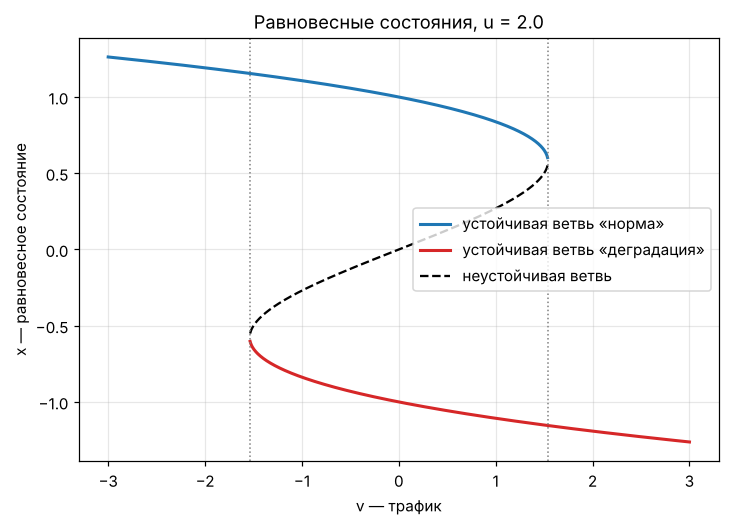

In [ ]:
v_grid = np.linspace(-v_max, v_max, 1201)
branches = {"upper": [], "mid": [], "lower": []}
for vv_ in v_grid:
    r = equilibria(vv_, u)
    if len(r) == 3:
        branches["lower"].append((vv_, r[0])); branches["mid"].append((vv_, r[1])); branches["upper"].append((vv_, r[2]))
    else:
        # одно равновесие: относим к ветви, которой оно непрерывно принадлежит
        (branches["upper"] if vv_ < 0 else branches["lower"]).append((vv_, r[0]))

def arr(b): 
    a = np.array(b); return a[:, 0], a[:, 1]

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(*arr(branches["upper"]), "tab:blue", lw=2, label="устойчивая ветвь «норма»")
ax.plot(*arr(branches["lower"]), "tab:red", lw=2, label="устойчивая ветвь «деградация»")
ax.plot(*arr(branches["mid"]), "k--", lw=1.5, label="неустойчивая ветвь")
for s in (-1, 1):
    ax.axvline(s*v_c, color="gray", ls=":", lw=1)
ax.set_xlabel("v — трафик"); ax.set_ylabel("x — равновесное состояние")
ax.set_title(f"Равновесные состояния, u = {u}")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## 5. Численное моделирование динамики

Решаем $\dot x=-(4x^3-2ux+v(t))$, где трафик меняется **медленно и линейно**: $v(t)=v_0+\mathrm{sgn}\cdot r\,t$ ($r$ — скорость изменения).

* **Эксперимент A (Forward):** старт при низкой нагрузке $v=-3$ в равновесии, затем рост до $v=+3$.
* **Эксперимент B (Reverse):** старт с **конечного состояния** эксперимента A при $v=+3$, затем снижение до $v=-3$.

In [ ]:
def simulate(x0, v_start, v_end, rate, u, n_points=6000):
    # интегрирует x' = -(4x^3 - 2ux + v(t)) при линейно меняющемся v(t)
    s = np.sign(v_end - v_start)
    T = abs(v_end - v_start) / rate
    v_of_t = lambda t: v_start + s*rate*t
    rhs = lambda t, y: [force(y[0], u, v_of_t(t))]
    t_eval = np.linspace(0, T, n_points)
    sol = solve_ivp(rhs, (0, T), [x0], t_eval=t_eval, rtol=1e-9, atol=1e-11)
    return sol.t, sol.y[0], v_of_t(sol.t)

# Эксперимент A: рост нагрузки
x_start = equilibria(-v_max, u)[-1]            # устойчивое «нормальное» состояние при v = -3
tA, xA, vA = simulate(x_start, -v_max, +v_max, rate, u)

# Эксперимент B: снижение нагрузки, старт с конечного состояния эксперимента A
tB, xB, vB = simulate(xA[-1], +v_max, -v_max, rate, u)

def jump_point(x, v, direction):
    # момент катастрофы: смена знака x (прыжок между ветвями «норма» и «деградация»)
    i = np.argmax(x < 0) if direction == "up" else np.argmax(x > 0)
    return i, v[i]

iA, v_jumpA = jump_point(xA, vA, "up")
iB, v_jumpB = jump_point(xB, vB, "down")
dxA = np.abs(np.gradient(xA, tA)); iA_max = np.argmax(dxA)     # момент максимальной скорости прыжка
dxB = np.abs(np.gradient(xB, tB)); iB_max = np.argmax(dxB)

print(f"Старт эксперимента A: v = {-v_max}, x = {x_start:.4f}")
print(f"Конец эксперимента A: v = {vA[-1]:.1f}, x = {xA[-1]:.4f}   (другая ветвь!)")
print(f"Конец эксперимента B: v = {vB[-1]:.1f}, x = {xB[-1]:.4f}")
print()
print(f"Теоретическая точка катастрофы:           v = ±{v_c:.4f}")
print(f"Прыжок при росте нагрузки (Forward):      v = {v_jumpA:+.4f}  (макс. скорость при v = {vA[iA_max]:+.4f})")
print(f"Прыжок при падении нагрузки (Reverse):    v = {v_jumpB:+.4f}  (макс. скорость при v = {vB[iB_max]:+.4f})")
print(f"Ширина петли гистерезиса:                 {v_jumpA - v_jumpB:.4f}   (теория для r -> 0: 2*v_c = {2*v_c:.4f})")
print(f"Величина скачка x:  при росте {xA[min(iA+300, len(xA)-1)] - xA[max(iA-300,0)]:+.3f},  при падении {xB[min(iB+300, len(xB)-1)] - xB[max(iB-300,0)]:+.3f}")

Старт эксперимента A: v = -3.0, x = 1.2626
Конец эксперимента A: v = 3.0, x = -1.2625   (другая ветвь!)
Конец эксперимента B: v = -3.0, x = 1.2625

Теоретическая точка катастрофы:           v = ±1.5396
Прыжок при росте нагрузки (Forward):      v = +1.5958  (макс. скорость при v = +1.5978)
Прыжок при падении нагрузки (Reverse):    v = -1.5958  (макс. скорость при v = -1.5978)
Ширина петли гистерезиса:                 3.1915   (теория для r -> 0: 2*v_c = 3.0792)
Величина скачка x:  при росте -1.941,  при падении +1.941


## 6. Анализ результатов

### 6.1. Петля гистерезиса $x(v)$

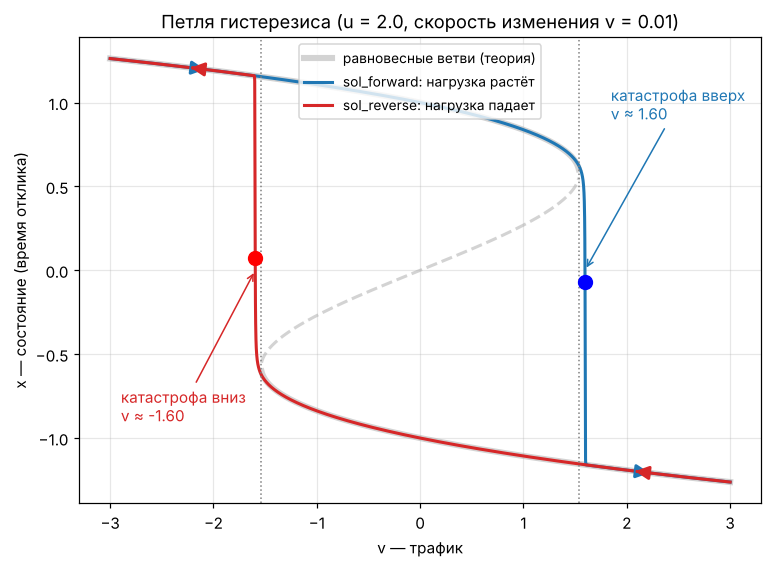

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(*arr(branches["upper"]), color="lightgray", lw=4, zorder=0)
ax.plot(*arr(branches["lower"]), color="lightgray", lw=4, zorder=0, label="равновесные ветви (теория)")
ax.plot(*arr(branches["mid"]), color="lightgray", lw=2, ls="--", zorder=0)

ax.plot(vA, xA, color="tab:blue", lw=2, label="sol_forward: нагрузка растёт")
ax.plot(vB, xB, color="tab:red", lw=2, label="sol_reverse: нагрузка падает")

# стрелки направления движения
def arrow(v_arr, x_arr, i, c):
    ax.annotate("", xy=(v_arr[i+20], x_arr[i+20]), xytext=(v_arr[i], x_arr[i]),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=2, mutation_scale=18))
arrow(vA, xA, 900, "tab:blue"); arrow(vA, xA, 5200, "tab:blue")
arrow(vB, xB, 900, "tab:red");  arrow(vB, xB, 5200, "tab:red")

for s in (-1, 1):
    ax.axvline(s*v_c, color="gray", ls=":", lw=1)
ax.plot([v_jumpA], [xA[iA]], "bo", ms=9, zorder=5)
ax.plot([v_jumpB], [xB[iB]], "ro", ms=9, zorder=5)
ax.annotate(f"катастрофа вверх\nv ≈ {v_jumpA:.2f}", (v_jumpA, 0), xytext=(v_jumpA + 0.25, 0.9), color="tab:blue",
            arrowprops=dict(arrowstyle="->", color="tab:blue"))
ax.annotate(f"катастрофа вниз\nv ≈ {v_jumpB:.2f}", (v_jumpB, 0), xytext=(v_jumpB - 1.3, -0.9), color="tab:red",
            arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set_xlabel("v — трафик"); ax.set_ylabel("x — состояние (время отклика)")
ax.set_title(f"Петля гистерезиса (u = {u}, скорость изменения v = {rate})")
ax.legend(loc="upper center", fontsize=9); ax.grid(alpha=0.3)
plt.show()

### 6.2. Динамика во времени: $x(t)$ и $v(t)$ для обоих экспериментов

Эксперимент B продолжает эксперимент A по времени (общая ось $t$).

Скачок при росте нагрузки произошёл в момент t = 459.6  (v = +1.596)
Скачок при падении нагрузки произошёл в момент t = 1059.6  (v = -1.596)
Интервал времени между скачками при развороте тренда: 600.0


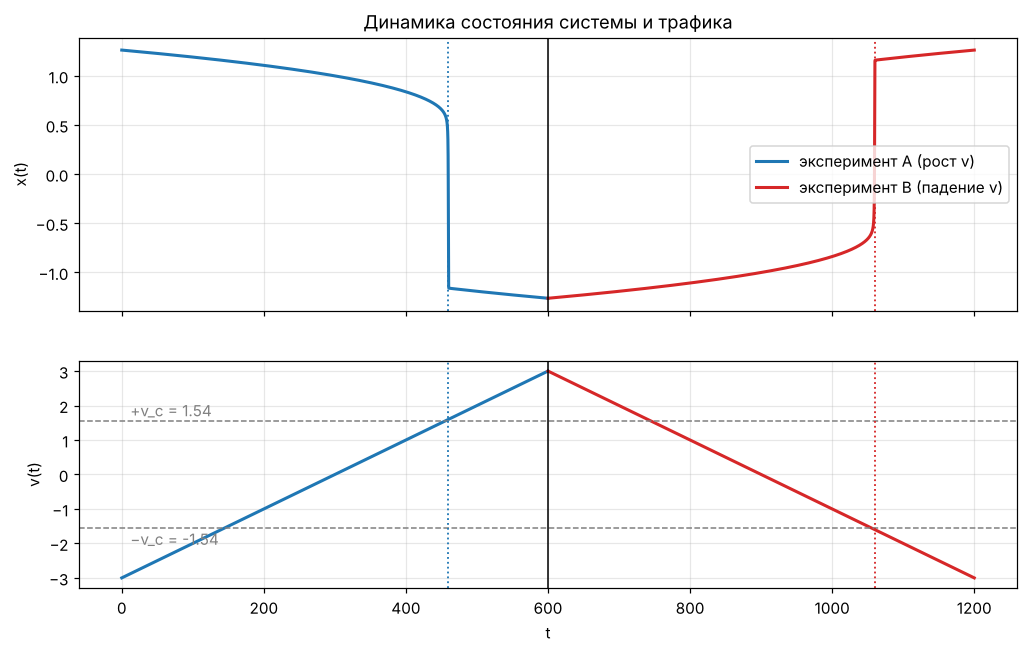

In [ ]:
t_all = np.concatenate([tA, tB + tA[-1]])
x_all = np.concatenate([xA, xB])
v_all = np.concatenate([vA, vB])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
ax1.plot(tA, xA, color="tab:blue", lw=2, label="эксперимент A (рост v)")
ax1.plot(tB + tA[-1], xB, color="tab:red", lw=2, label="эксперимент B (падение v)")
ax1.axvline(tA[iA], color="tab:blue", ls=":", lw=1.2)
ax1.axvline(tB[iB] + tA[-1], color="tab:red", ls=":", lw=1.2)
ax1.axvline(tA[-1], color="k", lw=1)
ax1.set_ylabel("x(t)"); ax1.legend(loc="center right"); ax1.grid(alpha=0.3)
ax1.set_title("Динамика состояния системы и трафика")

ax2.plot(tA, vA, color="tab:blue", lw=2)
ax2.plot(tB + tA[-1], vB, color="tab:red", lw=2)
ax2.axhline(v_c, color="gray", ls="--", lw=1); ax2.axhline(-v_c, color="gray", ls="--", lw=1)
ax2.text(t_all[-1]*0.01, v_c + 0.15, f"+v_c = {v_c:.2f}", color="gray")
ax2.text(t_all[-1]*0.01, -v_c - 0.5, f"−v_c = {-v_c:.2f}", color="gray")
ax2.axvline(tA[iA], color="tab:blue", ls=":", lw=1.2)
ax2.axvline(tB[iB] + tA[-1], color="tab:red", ls=":", lw=1.2)
ax2.axvline(tA[-1], color="k", lw=1)
ax2.set_xlabel("t"); ax2.set_ylabel("v(t)"); ax2.grid(alpha=0.3)
plt.show()

print(f"Скачок при росте нагрузки произошёл в момент t = {tA[iA]:.1f}  (v = {v_jumpA:+.3f})")
print(f"Скачок при падении нагрузки произошёл в момент t = {tB[iB] + tA[-1]:.1f}  (v = {v_jumpB:+.3f})")
print(f"Интервал времени между скачками при развороте тренда: {tB[iB] + tA[-1] - tA[iA]:.1f}")

## 7. Проверка и дополнительные исследования

### 7.1. Подтверждение гистерезиса: проверка, что одно и то же значение $v$ даёт разные состояния

Выберем несколько значений трафика внутри бистабильной зоны и сравним состояние системы на траекториях A и B.

In [ ]:
print(f"{'v':>6} {'x при росте (A)':>18} {'x при падении (B)':>20} {'разница':>10}")
for vv_ in [-1.2, -0.6, 0.0, 0.6, 1.2]:
    ia = np.argmin(np.abs(vA - vv_))
    ib = np.argmin(np.abs(vB - vv_))
    print(f"{vv_:6.2f} {xA[ia]:18.4f} {xB[ib]:20.4f} {xA[ia]-xB[ib]:10.4f}")

# Вне бистабильной зоны (|v| > прыжка) состояния должны совпасть — гистерезис исчезает
print()
print("Вне петли (трафик слишком мал или велик) ветви совпадают:")
for vv_ in [-2.5, 2.5]:
    ia = np.argmin(np.abs(vA - vv_)); ib = np.argmin(np.abs(vB - vv_))
    print(f"  v = {vv_:5.2f}:  x_A = {xA[ia]:.4f},  x_B = {xB[ib]:.4f},  разница {abs(xA[ia]-xB[ib]):.1e}")

# Проверка квазистатичности: вдали от скачка траектория лежит на равновесной ветви
mask = vA < v_c - 0.3
x_eq = np.array([equilibria(vv_, u)[-1] for vv_ in vA[mask]])
print(f"\nМакс. отклонение траектории A от равновесной ветви при v < v_c - 0.3: {np.max(np.abs(xA[mask] - x_eq)):.2e}")

     v    x при росте (A)    x при падении (B)    разница
 -1.20             1.1255              -0.7874     1.9129
 -0.60             1.0680              -0.9146     1.9826
  0.00             1.0002              -1.0002     2.0004
  0.60             0.9146              -1.0680     1.9826
  1.20             0.7874              -1.1255     1.9129

Вне петли (трафик слишком мал или велик) ветви совпадают:
  v = -2.50:  x_A = 1.2284,  x_B = 1.2283,  разница 1.0e-04
  v =  2.50:  x_A = -1.2283,  x_B = -1.2284,  разница 1.0e-04

Макс. отклонение траектории A от равновесной ветви при v < v_c - 0.3: 9.61e-04


### 7.2. Влияние скорости изменения трафика

Теория предсказывает, что петля имеет ширину $2v_c$ только при **бесконечно медленном** изменении $v$. При конечной скорости система «опаздывает» с прыжком (динамическая задержка) и петля становится шире.

 скорость r   v прыжка вверх   v прыжка вниз   ширина петли   избыток над 2v_c
      0.100           1.7863         -1.7863         3.5727             0.4935
      0.030           1.6536         -1.6536         3.3072             0.2280
      0.010           1.5958         -1.5958         3.1916             0.1124
      0.003           1.5651         -1.5651         3.1301             0.0509
      0.001           1.5523         -1.5523         3.1046             0.0254

Теоретический предел при r -> 0: ширина петли 2*v_c = 3.0792


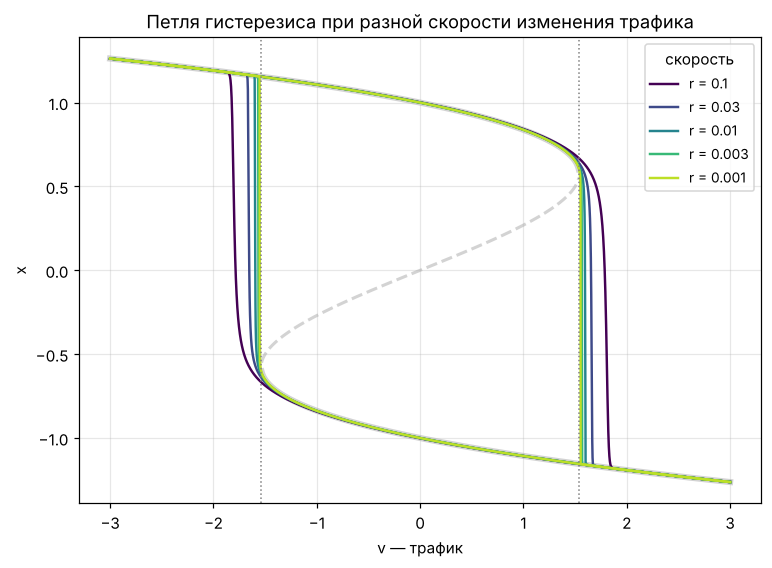

In [ ]:
rates = [0.1, 0.03, 0.01, 0.003, 0.001]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(*arr(branches["upper"]), color="lightgray", lw=4, zorder=0)
ax.plot(*arr(branches["lower"]), color="lightgray", lw=4, zorder=0)
ax.plot(*arr(branches["mid"]), color="lightgray", lw=2, ls="--", zorder=0)
cmap = plt.cm.viridis(np.linspace(0.0, 0.9, len(rates)))

print(f"{'скорость r':>11} {'v прыжка вверх':>16} {'v прыжка вниз':>15} {'ширина петли':>14} {'избыток над 2v_c':>18}")
widths = []
for r_, col in zip(rates, cmap):
    ta, xa, va = simulate(x_start, -v_max, v_max, r_, u, n_points=8000)
    tb, xb, vb = simulate(xa[-1], v_max, -v_max, r_, u, n_points=8000)
    _, vja = jump_point(xa, va, "up"); _, vjb = jump_point(xb, vb, "down")
    widths.append(vja - vjb)
    ax.plot(va, xa, color=col, lw=1.6, label=f"r = {r_}")
    ax.plot(vb, xb, color=col, lw=1.6)
    print(f"{r_:11.3f} {vja:16.4f} {vjb:15.4f} {vja - vjb:14.4f} {vja - vjb - 2*v_c:18.4f}")
for s in (-1, 1):
    ax.axvline(s*v_c, color="gray", ls=":", lw=1)
ax.set_xlabel("v — трафик"); ax.set_ylabel("x")
ax.set_title("Петля гистерезиса при разной скорости изменения трафика")
ax.legend(title="скорость", fontsize=9); ax.grid(alpha=0.3)
plt.show()
print(f"\nТеоретический предел при r -> 0: ширина петли 2*v_c = {2*v_c:.4f}")

### 7.3. Влияние числа серверов $u$: проверка бифуркационного множества

Ширина петли должна быть равна $2v_c(u)=2\sqrt{8u^3/27}$ — то есть точки скачков при медленном изменении трафика лежат на кривой $8u^3=27v^2$. Проверим это для разных $u$.

    u  v_c теория    v вверх     v вниз    ширина    2*v_c  отн. ошибка
 0.50      0.1925     0.2158    -0.2158    0.4316   0.3849        12.1%
 1.00      0.5443     0.5657    -0.5657    1.1314   1.0887         3.9%
 1.50      1.0000     1.0204    -1.0204    2.0407   2.0000         2.0%
 2.00      1.5396     1.5592    -1.5592    3.1183   3.0792         1.3%
 3.00      2.8284     2.8471    -2.8471    5.6942   5.6569         0.7%
 4.00      4.3546     4.3721    -4.3721    8.7442   8.7093         0.4%


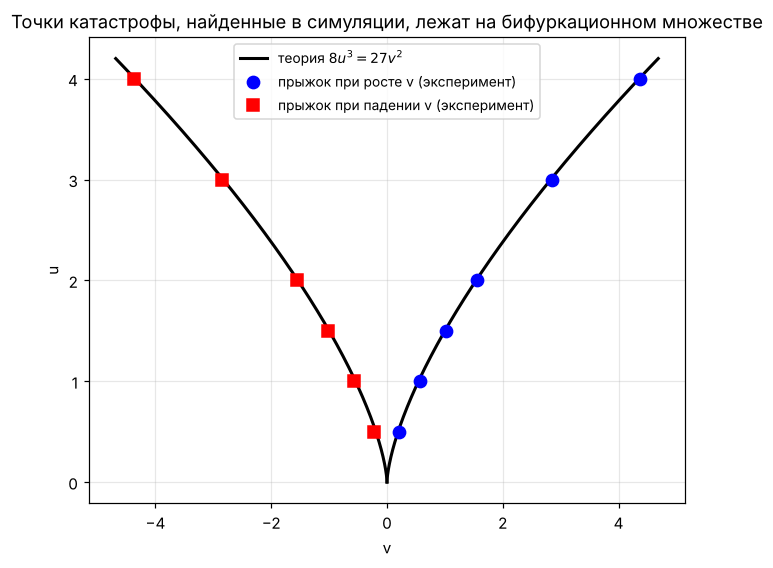

In [ ]:
u_list = [0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
r_slow = 0.002
meas_up, meas_down, theo = [], [], []

print(f"{'u':>5} {'v_c теория':>11} {'v вверх':>10} {'v вниз':>10} {'ширина':>9} {'2*v_c':>8} {'отн. ошибка':>12}")
for uu_ in u_list:
    vc_ = np.sqrt(8*uu_**3/27)
    vm = vc_ + 1.5
    x0_ = equilibria(-vm, uu_)[-1]
    ta, xa, va = simulate(x0_, -vm, vm, r_slow, uu_, n_points=10000)
    tb, xb, vb = simulate(xa[-1], vm, -vm, r_slow, uu_, n_points=10000)
    _, vja = jump_point(xa, va, "up"); _, vjb = jump_point(xb, vb, "down")
    meas_up.append(vja); meas_down.append(vjb); theo.append(vc_)
    print(f"{uu_:5.2f} {vc_:11.4f} {vja:10.4f} {vjb:10.4f} {vja-vjb:9.4f} {2*vc_:8.4f} {(vja-vjb-2*vc_)/(2*vc_):12.1%}")

fig, ax = plt.subplots(figsize=(7, 5.5))
uu = np.linspace(0, 4.2, 300); vv = np.sqrt(8*uu**3/27)
ax.plot(vv, uu, "k", lw=2, label=r"теория $8u^3=27v^2$"); ax.plot(-vv, uu, "k", lw=2)
ax.plot(meas_up, u_list, "bo", ms=8, label="прыжок при росте v (эксперимент)")
ax.plot(meas_down, u_list, "rs", ms=8, label="прыжок при падении v (эксперимент)")
ax.set_xlabel("v"); ax.set_ylabel("u"); ax.set_title("Точки катастрофы, найденные в симуляции, лежат на бифуркационном множестве")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

## 8. Выводы по эксперименту

* **Точка катастрофы.** При $u=2$ теория даёт $|v_c|=\sqrt{8u^3/27}\approx1.540$. В симуляции при $r=0.01$ скачок «норма → деградация» произошёл при $v\approx+1.596$, а «деградация → норма» — при $v\approx-1.596$. Небольшое превышение над $1.540$ — динамическая задержка из-за конечной скорости изменения $v$; при уменьшении $r$ точки скачков приближаются к теоретическим (см. п. 7.2).
* **Гистерезис подтверждён.** На интервале $-1.54<v<1.54$ одному и тому же значению трафика соответствуют два разных состояния системы — какое именно, зависит от того, **откуда** пришла система (п. 7.1). Вне этого интервала траектории A и B совпадают.
* **Скачок, а не плавный рост.** Трафик менялся плавно и линейно, а состояние $x$ при достижении $v_c$ изменилось скачком (с $x\approx+0.6$ до $x\approx-1.2$, около 1.9 единицы).
* **Проверка по теории.** Точки скачков при разных $u$ ложатся на кривую $8u^3=27v^2$ (п. 7.3): отклонение от теории составляет от 12% при $u=0.5$ до 0.4% при $u=4$ и целиком объясняется конечной скоростью изменения $v$ (при малых $u$ критическое $v_c$ мало, и абсолютная задержка заметнее в относительном выражении).

**Замечание об интерпретации.** В модели $x$ и $v$ — безразмерные отклонения от некоторых базовых уровней, поэтому могут быть отрицательными; реальное время отклика положительно. Ветвь $x>0$ можно интерпретировать как режим «норма», а $x<0$ — как режим «деградация» (между ними находится неустойчивое равновесие $x=0$ при $v=0$). Важна не абсолютная шкала, а качественная картина: два режима и скачки между ними.

## 9. Ответы на вопросы для отчёта

**1. Почему после того, как нагрузка начала падать, время отклика не сразу вернулось к исходному низкому уровню?**

В зоне $|v|<v_c$ потенциал имеет **два минимума**, и система находится в том, в котором оказалась раньше. После скачка в «деградированное» состояние нагрузка стала снижаться, но этот минимум продолжает существовать, пока $v>-v_c$: система просто «скатывается» по нему и остаётся на нижней ветви. Чтобы вернуться, нужно, чтобы этот минимум **исчез** (потенциальная яма «схлопнулась»), а это происходит только при $v\approx-v_c$, то есть когда нагрузка упала намного ниже той, при которой сбой произошёл. Состояние системы определяется не только текущим значением параметра, но и **историей** — это и есть гистерезис.

**2. Как этот эффект объясняет реальные ситуации, когда сервис падает при нагрузке ниже пиковой?**

Сбой определяется не абсолютным значением нагрузки, а тем, **в какой ветви** находится система. Если сервис уже оказался в деградированном режиме (очереди, перегретые кэши, исчерпанные пулы соединений, каскад ретраев), он остаётся в нём и при нагрузке, которая раньше обслуживалась нормально — даже ниже той, при которой всё начало ломаться. Аналогично, небольшое превышение критического значения $v_c$ даёт внезапный скачок, хотя плавная экстраполяция метрик ничего подобного не предсказывала. Поэтому «средняя» или «ниже пиковой» нагрузка не гарантирует безопасности: решает история и положение относительно границы бистабильной зоны.

**3. Какие практические рекомендации для мониторинга и проектирования систем можно извлечь из наличия гистерезиса?**

* *Мониторинг:* следить не только за значением метрики, но и за **запасом до критической точки** и скоростью приближения к ней; оповещения должны срабатывать **до** $v_c$, а не после скачка. Отслеживать направление изменения (рост/спад) и режим системы, а не только среднюю нагрузку.
* *Масштабирование:* $v_c\propto u^{3/2}$ — добавление серверов расширяет безопасную зону, но делает нелинейно более широкой и петлю гистерезиса, поэтому масштабироваться нужно **заранее**, а не в момент сбоя.
* *Восстановление:* после сбоя недостаточно «вернуть нагрузку к норме» — нужно снизить её **значительно ниже** порога сбоя (или временно сбросить, ограничить входящий поток, перезапустить/«охладить» систему), пока не исчезнет деградированный минимум. Полезны ограничения скорости запросов (rate limiting), backpressure, circuit breaker и плавное, а не мгновенное возвращение трафика.
* *Тестирование:* нагрузочные тесты нужно проводить **в обоих направлениях** (рост и спад) и сравнивать петлю; один прогон «вверх» гистерезис не покажет.
* *Проектирование:* добавлять демпфирование и обратные связи (ограничение ретраев, таймауты, автоскейлинг с запасом), чтобы уменьшить площадь бистабильной зоны.